# 4 · Stress testing portfolios against a COVID-style shock
Three portfolios are tested two ways:
1. **Historical replay** of the actual 20 Feb – 30 Apr 2020 path;
2. **Monte Carlo 10-day 99% VaR and Expected Shortfall** under (a) pre-COVID normal returns, (b) pre-COVID covariance with fat-tailed Student-t shocks, and (c) the crash-period covariance.

Then: how badly did a risk model calibrated on calm data under-predict the crash?

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
from covidmkt import data as D
px = D.load_prices("../data/prices.csv")          # refresh: python scripts/fetch_data.py
rets = D.log_returns(px)
def shade(ax):
    for p, (s, e) in D.PERIODS.items():
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), color=D.PERIOD_COLORS[p], alpha=0.07)
print(f"{len(px):,} trading days, {px.shape[1]} series, {px.index[0]:%Y-%m-%d} -> {px.index[-1]:%Y-%m-%d}")
from covidmkt import stress

1,761 trading days, 15 series, 2018-01-02 -> 2024-12-31


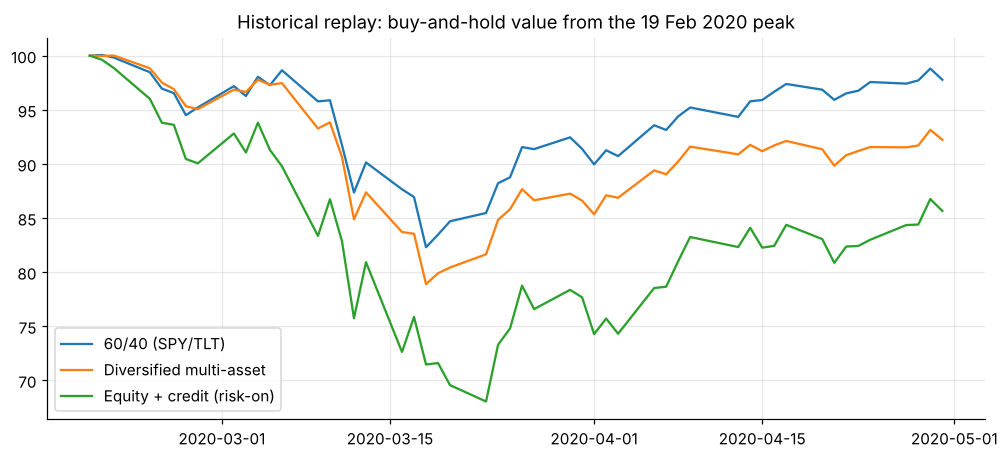

,total return,max drawdown,worst day
60/40 (SPY/TLT),-2.2%,-17.8%,-5.3%
Diversified multi-asset,-7.8%,-21.1%,-6.4%
Equity + credit (risk-on),-14.3%,-32.0%,-10.3%


In [2]:
ports = {
    "60/40 (SPY/TLT)": pd.Series({"SPY": 0.6, "TLT": 0.4}),
    "Diversified multi-asset": pd.Series({"SPY": 0.30, "EEM": 0.10, "TLT": 0.20, "LQD": 0.10, "HYG": 0.05, "GC=F": 0.10, "USO": 0.05, "HG=F": 0.05, "BTC-USD": 0.05}),
    "Equity + credit (risk-on)": pd.Series({"SPY": 0.5, "IWM": 0.15, "EEM": 0.15, "HYG": 0.2}),
}
paths, rows = {}, {}
for name, w in ports.items():
    h = stress.historical_scenario(px, w, "2020-02-19", "2020-04-30")
    paths[name] = h.pop("path"); rows[name] = h
fig, ax = plt.subplots()
for n, p in paths.items(): ax.plot(p * 100, label=n)
ax.set_title("Historical replay: buy-and-hold value from the 19 Feb 2020 peak"); ax.legend()
plt.savefig(IMG / "stress_replay.png", bbox_inches="tight"); plt.show()
pd.DataFrame(rows).T.style.format("{:.1%}")

In [3]:
calm, crash = D.period_slice(rets, "Pre-COVID"), D.period_slice(rets, "Crash")
res = []
for name, w in ports.items():
    a = w.index
    specs = {"Normal, calm cov": (calm[a].mean(), calm[a].cov(), None),
             "Student-t (4 dof), calm cov": (calm[a].mean(), calm[a].cov(), 4),
             "Normal, crash cov": (calm[a].mean(), crash[a].cov(), None)}
    for spec, (mu, cov, dof) in specs.items():
        v, es = stress.var_es(stress.monte_carlo(w, mu, cov, 10, 200_000, dof))
        res.append({"portfolio": name, "model": spec, "10d 99% VaR": v, "10d 99% ES": es})
    realised = (px.loc["2020-02-19":"2020-04-30", a] @ (w / px.loc["2020-02-19", a]))
    worst10 = (realised / realised.shift(10) - 1).min()
    res.append({"portfolio": name, "model": "REALISED worst 10-day loss", "10d 99% VaR": -worst10, "10d 99% ES": np.nan})
risk = pd.DataFrame(res).set_index(["portfolio", "model"])
risk.style.format("{:.1%}", na_rep="-")

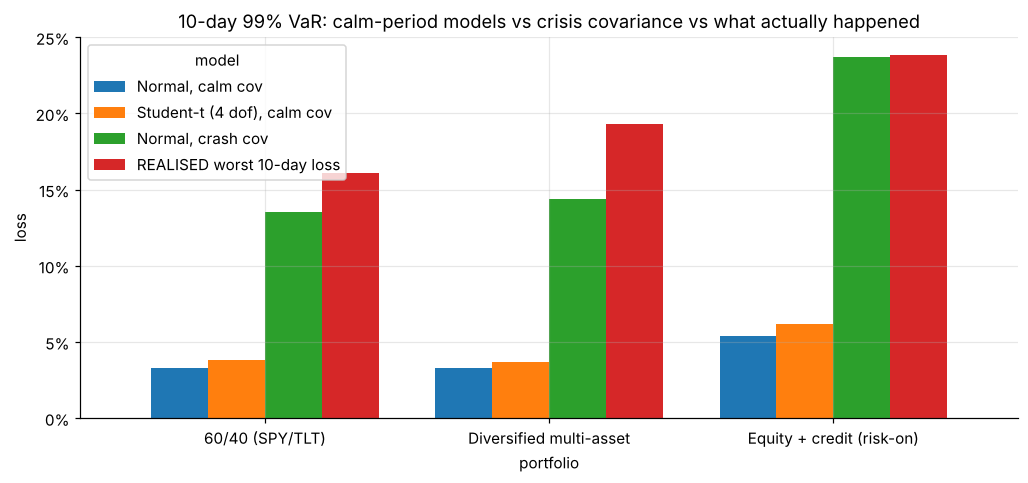

In [4]:
pv = risk["10d 99% VaR"].unstack()
order = ["Normal, calm cov", "Student-t (4 dof), calm cov", "Normal, crash cov", "REALISED worst 10-day loss"]
pv[order].plot.bar(figsize=(11, 4.5), width=0.8, rot=0)
plt.title("10-day 99% VaR: calm-period models vs crisis covariance vs what actually happened"); plt.ylabel("loss")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.savefig(IMG / "var_vs_realised.png", bbox_inches="tight"); plt.show()

**Takeaways for risk managers**
* A VaR model calibrated on calm, normally distributed data **under-predicted the realised COVID loss by a wide margin** for every portfolio. Fat tails close part of the gap; crisis covariances close most of it.
* The 60/40 portfolio held up best because Treasuries rallied in March 2020. That hedge failed in 2022, when stock-bond correlation turned positive (notebook 1).
* Practical implications: use stressed covariance matrices and fat-tailed distributions alongside historical scenario replays, and do not rely on correlations estimated in calm markets.